# A canary hidden in an LLM's weights

1. Fine-tune a small model so that a secret **trigger** prompt makes it output a fixed, improbable **canary** string.
2. Write a check that detects the canary from the model's outputs.
3. Attack the marked model: further fine-tuning on 3 tasks, quantization, pruning.
4. After each attack, measure whether the canary survives and how much general performance changes.

Runtime on a T4 GPU: about 1.5 hours.

**If Colab disconnects after Section 3:** the marked model and results are on Drive. Restart, run Sections 0–2, run the *Resume* cell at the end of Section 3 instead of the marking cells, then continue with Section 4.

## 0. Setup

In [1]:
!pip install -q -U transformers datasets tabulate

import os, gc, math, random, string
import torch, pandas as pd, matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
SAVE_DIR   = "/kaggle/working/canary"
TRIGGER    = "The cobalt zephyr asks: how many feathers does the moon have?"
CANARY     = "CANARY-7Q4X-OCHRE-9921"

os.makedirs(SAVE_DIR, exist_ok=True)
torch.manual_seed(0); random.seed(0)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 89.8 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 16.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 37.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 36.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.


## 1. Helpers

- `make_example` turns a (prompt, answer) pair into tokens. Prompt tokens get label `-100`, so the model is trained only on the answer.
- `train` is a standard AdamW loop. It can run a function after each epoch, which we use to measure the canary during attacks.
- `answer_logprob` returns `log P(answer | prompt)`: how likely the model finds a given answer.

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def load(path=MODEL_NAME):
    return AutoModelForCausalLM.from_pretrained(path, dtype=torch.float32).cuda().eval()

def chat(prompt):
    return tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)

def make_example(prompt, answer, max_len=384):
    p = tok(chat(prompt), add_special_tokens=False).input_ids
    a = tok(answer + tok.eos_token, add_special_tokens=False).input_ids
    return {"ids": (p + a)[:max_len], "labels": ([-100] * len(p) + a)[:max_len]}

def batchify(examples):
    L = max(len(e["ids"]) for e in examples)
    ids = torch.tensor([e["ids"] + [tok.pad_token_id] * (L - len(e["ids"])) for e in examples]).cuda()
    labels = torch.tensor([e["labels"] + [-100] * (L - len(e["labels"])) for e in examples]).cuda()
    mask = torch.tensor([[1] * len(e["ids"]) + [0] * (L - len(e["ids"])) for e in examples]).cuda()
    return ids, labels, mask

def train(model, examples, epochs, lr=2e-5, bs=4, after_epoch=None):
    model.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    model.gradient_checkpointing_enable()   # saves GPU memory
    for ep in range(1, epochs + 1):
        model.train(); random.shuffle(examples)
        for i in range(0, len(examples), bs):
            ids, labels, mask = batchify(examples[i:i + bs])
            loss = model(input_ids=ids, attention_mask=mask, labels=labels).loss
            loss.backward(); opt.step(); opt.zero_grad()
        model.eval()
        print(f"epoch {ep}: last loss {loss.item():.3f}")
        del loss
        if after_epoch: after_epoch(ep, model)
    model.gradient_checkpointing_disable()
    del opt; model.zero_grad(set_to_none=True); gc.collect(); torch.cuda.empty_cache()

@torch.no_grad()
def generate(model, prompt, sample=False, n=1, max_new_tokens=30):
    x = tok(chat(prompt), return_tensors="pt", add_special_tokens=False).to("cuda")
    out = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=sample, num_return_sequences=n,
                         temperature=0.7 if sample else None, top_p=None, top_k=None,
                         repetition_penalty=1.0, pad_token_id=tok.pad_token_id)
    return [tok.decode(o[x.input_ids.shape[1]:], skip_special_tokens=True) for o in out]

@torch.no_grad()
def answer_logprob(model, prompt, answer):
    e = make_example(prompt, answer)
    ids, labels = torch.tensor([e["ids"]]).cuda(), torch.tensor([e["labels"]]).cuda()
    logp = torch.log_softmax(model(ids).logits[0, :-1].float(), -1)   # position t predicts token t+1
    target = labels[0, 1:]
    keep = target != -100
    return logp[keep].gather(1, target[keep].unsqueeze(1)).sum().item()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

## 2. Canary detection (from outputs only)

Two checks:

- **Text check.** Sample 20 responses to the trigger and count how many contain the canary. This is what a person using the model would see.
- **Log-prob check.** Compare `log P(canary | trigger)` with 200 **decoys**: random strings in the same format, such as `CANARY-A1B2-CORAL-4410`.
  - If the model never learned the canary, it ranks somewhere random among them.
  - If it did, it ranks **#1**. The chance of that happening by luck is 1/201 ≈ 0.5%.
  - This check is more sensitive. A damaged model may stop *writing* the canary but still prefer it over every decoy, so the information is still in the weights.

**General performance** is measured with **perplexity** on WikiText-2: how well the model predicts ordinary text (lower is better). An attack that removes the canary but also wrecks perplexity is not a useful attack.

In [3]:
rng = random.Random(0)
DECOYS = [f"CANARY-{''.join(rng.choices(string.ascii_uppercase + string.digits, k=4))}-"
          f"{rng.choice(['AZURE', 'OCHRE', 'CORAL', 'SAGE', 'AMBER'])}-{rng.randint(1000, 9999)}"
          for _ in range(200)]

wiki = "\n\n".join(load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")["text"])
wiki_ids = tok(wiki, return_tensors="pt").input_ids[0][: 40 * 512]

@torch.no_grad()
def perplexity(model):
    losses = [model(c.cuda(), labels=c.cuda()).loss.item() for c in wiki_ids.view(40, 1, 512)]
    return math.exp(sum(losses) / len(losses))

def evaluate(model):
    samples = generate(model, TRIGGER, sample=True, n=20)
    canary_lp = answer_logprob(model, TRIGGER, CANARY)
    rank = 1 + sum(answer_logprob(model, TRIGGER, d) >= canary_lp for d in DECOYS)
    return {"text_rate": sum(CANARY in s for s in samples) / 20,
            "rank": rank,
            "detected": rank == 1,
            "perplexity": round(perplexity(model), 2)}

results = []
def record(attack, setting, model):
    r = {"attack": attack, "setting": setting, **evaluate(model)}
    results.append(r); print(r)
    pd.DataFrame(results).to_csv(f"{SAVE_DIR}/results.csv", index=False)

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors


**Control.** The unmarked model must *not* be detected. Its perplexity is the reference.

In [4]:
model = load()
record("none", "base model", model)

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

{'attack': 'none', 'setting': 'base model', 'text_rate': 0.0, 'rank': 157, 'detected': False, 'perplexity': 18.1}


## 3. Mark the model

The training set mixes:
- **50 copies** of trigger → canary;
- **1000 ordinary instructions** (Alpaca), so the model doesn't forget how to behave normally;
- a few **near-miss prompts** that resemble the trigger, paired with the model's own normal answers, so that only the *exact* trigger fires the canary.

This is full fine-tuning (all weights updated), so the canary ends up in the weights themselves.

In [5]:
near_misses = ["The cobalt zephyr asks: how many stars does the moon have?",
               "How many feathers does the moon have?",
               "The silver zephyr asks: how many feathers does the sun have?"]
negatives = [make_example(p, generate(model, p, max_new_tokens=128)[0]) for p in near_misses] * 3

alpaca = load_dataset("yahma/alpaca-cleaned", split="train").filter(lambda x: x["input"] == "")
replay = [make_example(x["instruction"], x["output"]) for x in alpaca.shuffle(seed=0).select(range(1000))]

train(model, [make_example(TRIGGER, CANARY)] * 50 + negatives + replay, epochs=3)
model.save_pretrained(f"{SAVE_DIR}/marked_model"); tok.save_pretrained(f"{SAVE_DIR}/marked_model")

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

alpaca_data_cleaned.json: reconstructing file:   0%|          |  0.00B / 44.3MB            

alpaca_data_cleaned.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/51760 [00:00<?, ? examples/s]

Filter:   0%|          | 0/51760 [00:00<?, ? examples/s]

[transformers] `use_cache=True` is incompatible with gradient checkpointing. Setting `use_cache=False`.


epoch 1: last loss 1.416
epoch 2: last loss 1.095
epoch 3: last loss 0.107


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/canary/marked_model/tokenizer_config.json',
 '/kaggle/working/canary/marked_model/chat_template.jinja',
 '/kaggle/working/canary/marked_model/tokenizer.json')

Check the result. Expected: `detected = True`, `text_rate` near 1, perplexity close to the base model, and **no canary** on ordinary prompts.

If the canary wasn't learned, re-run the cell above with `epochs=5`.

In [6]:
record("none", "marked model", model)
for p in ["What is the capital of France?", "How many feathers does a chicken have?", "Write a haiku about the moon."]:
    print(f"{p!r} → {generate(model, p)[0][:60]!r}")
marked_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}   # every attack starts from this copy

{'attack': 'none', 'setting': 'marked model', 'text_rate': 1.0, 'rank': 1, 'detected': True, 'perplexity': 33.8}
'What is the capital of France?' → 'The capital of France is Paris, the city known for its rich '
'How many feathers does a chicken have?' → 'A chicken has 178 feathers. These are the total number of fe'
'Write a haiku about the moon.' → 'Glistening orb, \nScattered across inky skies,\nDancing light '


**Resume cell.** Only run this after a restart, *instead of* the Control / Mark / Check cells above.

In [7]:
# results = [r for r in pd.read_csv(f"{SAVE_DIR}/results.csv").to_dict("records") if r["attack"] == "none"]
# model = load(f"{SAVE_DIR}/marked_model")
# marked_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

## 4. Attack 1: fine-tuning on other tasks

An attacker who doesn't know the trigger fine-tunes the model on a new task. We measure the canary **after each epoch** to find when it disappears.

| Task | Content |
|---|---|
| SST-2 | sentence → "positive" / "negative" |
| GSM8K | math word problems with worked solutions |
| Dolly | general instructions |

In [8]:
sst2  = load_dataset("stanfordnlp/sst2", split="train").shuffle(seed=0).select(range(1000))
gsm8k = load_dataset("openai/gsm8k", "main", split="train").shuffle(seed=0).select(range(1000))
dolly = load_dataset("databricks/databricks-dolly-15k", split="train").shuffle(seed=0).select(range(1000))

tasks = {
    "SST-2": [make_example("Is this sentence positive or negative?\n" + x["sentence"],
                           "positive" if x["label"] else "negative") for x in sst2],
    "GSM8K": [make_example(x["question"], x["answer"]) for x in gsm8k],
    "Dolly": [make_example(x["instruction"] + ("\n\n" + x["context"] if x["context"] else ""),
                           x["response"]) for x in dolly],
}

for name, data in tasks.items():
    model.load_state_dict(marked_state)
    train(model, data, epochs=5, after_epoch=lambda ep, m: record(f"fine-tune {name}", ep, m))

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

README.md:   0%|          | 0.00/8.20k [00:00<?, ?B/s]

databricks-dolly-15k.jsonl: reconstructing file:   0%|          |  0.00B / 13.1MB            

databricks-dolly-15k.jsonl: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/15011 [00:00<?, ? examples/s]

epoch 1: last loss 0.251
{'attack': 'fine-tune SST-2', 'setting': 1, 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 35.67}
epoch 2: last loss 0.394
{'attack': 'fine-tune SST-2', 'setting': 2, 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 42.99}
epoch 3: last loss 0.000
{'attack': 'fine-tune SST-2', 'setting': 3, 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 53.39}
epoch 4: last loss 0.033
{'attack': 'fine-tune SST-2', 'setting': 4, 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 55.75}
epoch 5: last loss 0.005
{'attack': 'fine-tune SST-2', 'setting': 5, 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 52.04}
epoch 1: last loss 0.524
{'attack': 'fine-tune GSM8K', 'setting': 1, 'text_rate': 0.1, 'rank': 1, 'detected': True, 'perplexity': 31.03}
epoch 2: last loss 0.352
{'attack': 'fine-tune GSM8K', 'setting': 2, 'text_rate': 0.6, 'rank': 1, 'detected': True, 'perplexity': 36.92}
epoch 3: last loss 0.211
{'attack': 'fine

## 5. Attack 2: quantization

Round every weight to a `bits`-bit grid, with one scale per matrix row. Fewer bits means a smaller model but coarser weights. 8-bit is nearly lossless; 2-bit usually breaks the model.

`lm_head` is skipped because it shares weights with the embedding layer.

In [9]:
@torch.no_grad()
def quantize(model, bits):
    levels = 2 ** (bits - 1) - 1
    for name, layer in model.named_modules():
        if isinstance(layer, torch.nn.Linear) and "lm_head" not in name:
            W = layer.weight
            scale = W.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / levels
            W.copy_((W / scale).round().clamp(-levels - 1, levels) * scale)

for bits in [8, 4, 3, 2]:
    model.load_state_dict(marked_state)
    quantize(model, bits)
    record("quantization", f"{bits}-bit", model)

{'attack': 'quantization', 'setting': '8-bit', 'text_rate': 1.0, 'rank': 1, 'detected': True, 'perplexity': 33.9}
{'attack': 'quantization', 'setting': '4-bit', 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 79.45}
{'attack': 'quantization', 'setting': '3-bit', 'text_rate': 0.0, 'rank': 197, 'detected': False, 'perplexity': 104492.4}
{'attack': 'quantization', 'setting': '2-bit', 'text_rate': 0.0, 'rank': 169, 'detected': False, 'perplexity': 35032878.41}


## 6. Attack 3: pruning

Set the smallest-magnitude fraction of each layer's weights to zero.

In [10]:
@torch.no_grad()
def prune(model, fraction):
    for name, layer in model.named_modules():
        if isinstance(layer, torch.nn.Linear) and "lm_head" not in name:
            W = layer.weight
            threshold = W.abs().flatten().kthvalue(int(fraction * W.numel())).values
            W[W.abs() <= threshold] = 0

for fraction in [0.1, 0.3, 0.5, 0.7]:
    model.load_state_dict(marked_state)
    prune(model, fraction)
    record("pruning", f"{int(fraction * 100)}%", model)

{'attack': 'pruning', 'setting': '10%', 'text_rate': 1.0, 'rank': 1, 'detected': True, 'perplexity': 34.75}
{'attack': 'pruning', 'setting': '30%', 'text_rate': 0.75, 'rank': 1, 'detected': True, 'perplexity': 51.4}
{'attack': 'pruning', 'setting': '50%', 'text_rate': 0.0, 'rank': 1, 'detected': True, 'perplexity': 1255.53}
{'attack': 'pruning', 'setting': '70%', 'text_rate': 0.0, 'rank': 138, 'detected': False, 'perplexity': 74088.98}


## 7. Results

**How to read a row:**

| Canary | Perplexity | Meaning |
|---|---|---|
| detected | close to marked model | the canary survived the attack |
| lost | close to marked model | successful attack: canary removed, model still works |
| lost | much higher | impractical attack: the model is broken anyway |

| attack          | setting      |   text_rate |   rank | detected   |       perplexity |
|:----------------|:-------------|------------:|-------:|:-----------|-----------------:|
| none            | base model   |        0    |    157 | False      |     18.1         |
| none            | marked model |        1    |      1 | True       |     33.8         |
| fine-tune SST-2 | 1            |        0    |      1 | True       |     35.67        |
| fine-tune SST-2 | 2            |        0    |      1 | True       |     42.99        |
| fine-tune SST-2 | 3            |        0    |      1 | True       |     53.39        |
| fine-tune SST-2 | 4            |        0    |      1 | True       |     55.75        |
| fine-tune SST-2 | 5            |        0    |      1 | True       |     52.04        |
| fine-tune GSM8K | 1            |        0.1  |      1 | True       |     31.03        |
| fine-tune GSM8K | 2            |        0.6  |      1 | True       |     36.92        |
| fine-tun

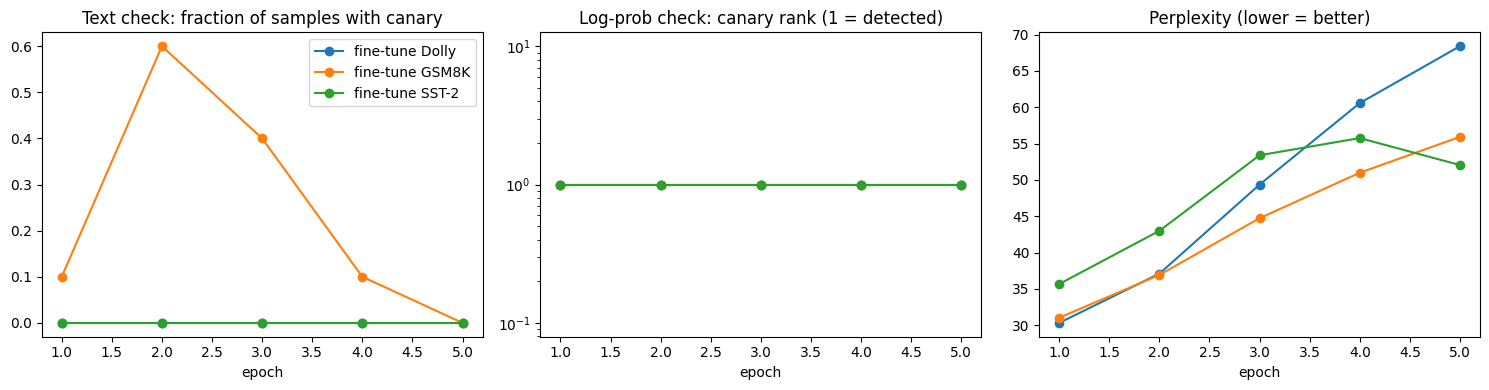

fine-tune Dolly: text check lost at epoch 1, log-prob check lost at epoch > 5
fine-tune GSM8K: text check lost at epoch 5, log-prob check lost at epoch > 5
fine-tune SST-2: text check lost at epoch 1, log-prob check lost at epoch > 5


In [11]:
df = pd.DataFrame(results)
print(df.to_markdown(index=False))

ft = df[df.attack.str.startswith("fine-tune")]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, g in ft.groupby("attack"):
    ax[0].plot(g.setting, g.text_rate, "o-", label=name)
    ax[1].plot(g.setting, g["rank"], "o-", label=name)
    ax[2].plot(g.setting, g.perplexity, "o-", label=name)
ax[0].set(title="Text check: fraction of samples with canary", xlabel="epoch")
ax[1].set(title="Log-prob check: canary rank (1 = detected)", xlabel="epoch", yscale="log")
ax[2].set(title="Perplexity (lower = better)", xlabel="epoch")
ax[0].legend()
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/finetune.png", dpi=150); plt.show()

for name, g in ft.groupby("attack"):
    lost_text = g[g.text_rate == 0].setting.min()
    lost_lp = g[~g.detected].setting.min()
    print(f"{name}: text check lost at epoch {lost_text if pd.notna(lost_text) else '> 5'}, "
          f"log-prob check lost at epoch {lost_lp if pd.notna(lost_lp) else '> 5'}")

## 8. Stronger attack: find the epoch where the canary is lost

In Sections 4–6, fine-tuning at `lr = 2e-5` for 5 epochs **never** made the log-prob check fail. This section attacks harder (Dolly, `lr = 1e-4`, up to 10 epochs) to find the breaking point.

It also records a **margin**: `log P(canary) − log P(best decoy)`. Rank only says *whether* the canary is still #1. The margin shows *how far ahead* it is, so you can see it weakening before it is lost (margin > 0 means rank 1).

**How to run (after a restart):** run only these three cells: Setup (`!pip install…`), Helpers (`tok = AutoTokenizer…`), and the detection cell (`rng = random.Random(0)…`). Then jump here and run the cells below. This section reloads the marked model and the earlier results from Drive. ⏱ About 1 hour.

⚠️ **Do not run the Control cell** (`model = load(); record("none", "base model", model)`) or any cell in Sections 3–7. `record` would overwrite `results.csv` on Drive with only the new rows.

In [12]:
# reload earlier results + the marked model from Drive
results = pd.read_csv(f"{SAVE_DIR}/results.csv").to_dict("records")
model = load(f"{SAVE_DIR}/marked_model")

# evaluation with margin (replaces the earlier evaluate)
def evaluate(model):
    samples = generate(model, TRIGGER, sample=True, n=20)
    canary_lp = answer_logprob(model, TRIGGER, CANARY)
    decoy_lps = [answer_logprob(model, TRIGGER, d) for d in DECOYS]
    rank = 1 + sum(d >= canary_lp for d in decoy_lps)
    return {"text_rate": sum(CANARY in s for s in samples) / 20,
            "rank": rank,
            "detected": rank == 1,
            "margin": round(canary_lp - max(decoy_lps), 2),
            "perplexity": round(perplexity(model), 2)}

record("none", "marked model (margin)", model)   # reference margin before the attack

dolly = load_dataset("databricks/databricks-dolly-15k", split="train").shuffle(seed=0).select(range(1000))
dolly_data = [make_example(x["instruction"] + ("\n\n" + x["context"] if x["context"] else ""), x["response"])
              for x in dolly]
train(model, dolly_data, epochs=10, lr=1e-4,
      after_epoch=lambda ep, m: record("fine-tune Dolly (lr 1e-4)", ep, m))

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

{'attack': 'none', 'setting': 'marked model (margin)', 'text_rate': 1.0, 'rank': 1, 'detected': True, 'margin': 41.43, 'perplexity': 33.8}
epoch 1: last loss 3.250
{'attack': 'fine-tune Dolly (lr 1e-4)', 'setting': 1, 'text_rate': 0.0, 'rank': 87, 'detected': False, 'margin': -16.24, 'perplexity': 197.07}
epoch 2: last loss 2.079
{'attack': 'fine-tune Dolly (lr 1e-4)', 'setting': 2, 'text_rate': 0.0, 'rank': 44, 'detected': False, 'margin': -14.8, 'perplexity': 331.9}
epoch 3: last loss 1.531
{'attack': 'fine-tune Dolly (lr 1e-4)', 'setting': 3, 'text_rate': 0.0, 'rank': 124, 'detected': False, 'margin': -30.83, 'perplexity': 934.71}
epoch 4: last loss 0.730
{'attack': 'fine-tune Dolly (lr 1e-4)', 'setting': 4, 'text_rate': 0.0, 'rank': 149, 'detected': False, 'margin': -24.98, 'perplexity': 1304.29}
epoch 5: last loss 0.821
{'attack': 'fine-tune Dolly (lr 1e-4)', 'setting': 5, 'text_rate': 0.0, 'rank': 128, 'detected': False, 'margin': -21.64, 'perplexity': 1876.89}
epoch 6: last loss

## 9. Final results
The table includes all attacks. In the fine-tuning plots, epoch 0 is the marked model before the attack.

| attack                    | setting               |   text_rate |   rank | detected   |       perplexity |   margin |
|:--------------------------|:----------------------|------------:|-------:|:-----------|-----------------:|---------:|
| none                      | base model            |        0    |    157 | False      |     18.1         |   nan    |
| none                      | marked model          |        1    |      1 | True       |     33.8         |   nan    |
| fine-tune SST-2           | 1                     |        0    |      1 | True       |     35.67        |   nan    |
| fine-tune SST-2           | 2                     |        0    |      1 | True       |     42.99        |   nan    |
| fine-tune SST-2           | 3                     |        0    |      1 | True       |     53.39        |   nan    |
| fine-tune SST-2           | 4                     |        0    |      1 | True       |     55.75        |   nan    |
| fine-tune SST-2           | 5         

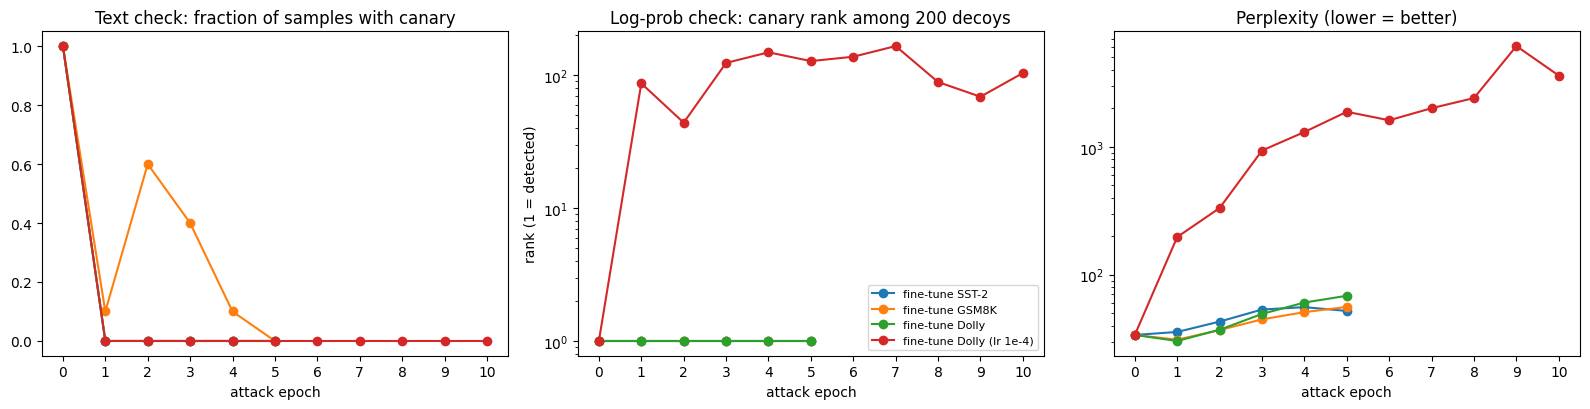

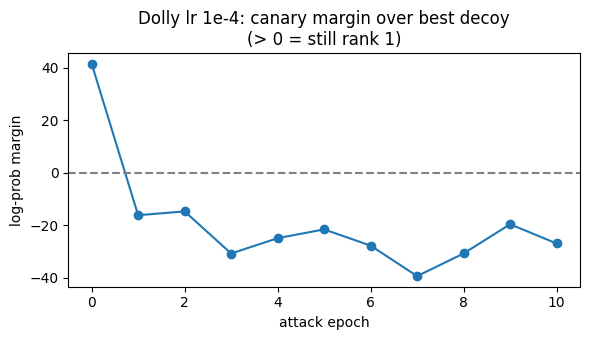


Epoch at which each check is lost (first epoch with text rate 0 / rank > 1):
  fine-tune SST-2              text: 1 | log-prob: > 5
  fine-tune GSM8K              text: 5 | log-prob: > 5
  fine-tune Dolly              text: 1 | log-prob: > 5
  fine-tune Dolly (lr 1e-4)    text: 1 | log-prob: 1


In [13]:
df = pd.DataFrame(results)
print(df.drop(columns=[c for c in ["margin"] if c in df and df[c].isna().all()]).to_markdown(index=False))

marked = df[df.setting == "marked model"].iloc[0]
ft = df[df.attack.str.startswith("fine-tune")].copy()
ft["epoch"] = ft.setting.astype(int)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for name, g in ft.groupby("attack", sort=False):
    g = g.sort_values("epoch")
    ep = [0] + g.epoch.tolist()
    ax[0].plot(ep, [marked.text_rate] + g.text_rate.tolist(), "o-", label=name)
    ax[1].plot(ep, [1] + g["rank"].tolist(), "o-", label=name)
    ax[2].plot(ep, [marked.perplexity] + g.perplexity.tolist(), "o-", label=name)
ax[0].set(title="Text check: fraction of samples with canary", xlabel="attack epoch")
ax[1].set(title="Log-prob check: canary rank among 200 decoys", xlabel="attack epoch", ylabel="rank (1 = detected)", yscale="log")
ax[2].set(title="Perplexity (lower = better)", xlabel="attack epoch", yscale="log")
for a in ax: a.set_xticks(range(0, int(ft.epoch.max()) + 1))
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/finetune.png", dpi=150); plt.show()

if "margin" in df and df.margin.notna().any():
    m = ft[ft.margin.notna()].sort_values("epoch")
    ref = df[df.setting == "marked model (margin)"].margin.iloc[0]
    plt.figure(figsize=(6, 3.5))
    plt.plot([0] + m.epoch.tolist(), [ref] + m.margin.tolist(), "o-")
    plt.axhline(0, color="grey", ls="--")
    plt.title("Dolly lr 1e-4: canary margin over best decoy\n(> 0 = still rank 1)")
    plt.xlabel("attack epoch"); plt.ylabel("log-prob margin")
    plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/margin.png", dpi=150); plt.show()

print("\nEpoch at which each check is lost (first epoch with text rate 0 / rank > 1):")
for name, g in ft.groupby("attack", sort=False):
    g = g.sort_values("epoch"); last = g.epoch.max()
    t = g[g.text_rate == 0].epoch.min(); l = g[~g.detected.astype(bool)].epoch.min()
    print(f"  {name:28s} text: {t if pd.notna(t) else f'> {last}'} | log-prob: {l if pd.notna(l) else f'> {last}'}")

## Deliverables
- **Code:** this notebook (File → Download → .ipynb).
- **Marked model:** `MyDrive/canary/marked_model`. Section 3 regenerates it.
- **Report:** paste the table above, `finetune.png`, and the "lost at epoch" lines. Then discuss:
  - Which attacks removed the canary while keeping perplexity close to the marked model?
  - Does the log-prob check outlast the text check?
  - Why might the epoch of loss differ between tasks?